In [52]:
pip install pandas matplotlib seaborn 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [53]:
# 1. Load the file into df. Print shape and dtypes.

import pandas as pd

df = pd.read_csv('meridian_daily_sales_raw - meridian_daily_sales_raw.csv')
print(df.shape)
print(df.dtypes)

(1627, 10)
store_id                str
store_name              str
region                  str
date                    str
transactions          int64
revenue                 str
avg_basket_value    float64
discount_pct            str
footfall              int64
stockout_flag           str
dtype: object


In [54]:
# 2. Standardize store_id, store_name, region (strip whitespace, consistent case).

df['store_id'] = df['store_id'].str.strip().str.lower()
print(df['store_id'].head())
df['store_name'] = df['store_name'].str.strip().str.lower()
print(df['store_name'].head())
df['region'] = df['region'].str.strip().str.lower()
print(df['region'].head())

0    st-10
1    st-13
2    st-16
3    st-14
4    st-04
Name: store_id, dtype: str
0    magnolia square
1     highland court
2    redwood station
3      golden valley
4    silverline mall
Name: store_name, dtype: str
0    south
1     west
2     west
3     west
4    north
Name: region, dtype: str


In [55]:
# 3. Parse date into a real date column. Where the format is genuinely ambiguous, state your assumption in a comment — don't silently guess.

df['date'] = pd.to_datetime(df['date'], dayfirst=True, errors='coerce')
print(df['date'].head())
print(df['date'].dtype)

0   2026-03-07
1   2026-05-27
2          NaT
3          NaT
4   2026-03-04
Name: date, dtype: datetime64[us]
datetime64[us]


In [56]:
# 4. Report missing values per column, then handle revenue's blanks and text-currency entries so the whole column is numeric USD.

print('Missing values before cleaning:')
print(df.isnull().sum())

# Clean 'revenue' column: remove '$', ',', and convert to numeric
df['revenue'] = df['revenue'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
df['revenue'] = pd.to_numeric(df['revenue'], errors='coerce')

# Fill NaN values in 'revenue' with 0 (or another appropriate strategy if needed)
df['revenue'] = df['revenue'].fillna(0)

print('\nMissing values after cleaning (revenue should be 0 for NaNs):')
print(df.isnull().sum())
print('\nRevenue column dtypes after cleaning:')
print(df['revenue'].dtype)
print('\nFirst 5 rows of revenue column after cleaning:')
print(df['revenue'].head())

Missing values before cleaning:
store_id               0
store_name             0
region                 0
date                1229
transactions           0
revenue               53
avg_basket_value       0
discount_pct           0
footfall               0
stockout_flag          0
dtype: int64

Missing values after cleaning (revenue should be 0 for NaNs):
store_id               0
store_name             0
region                 0
date                1229
transactions           0
revenue                0
avg_basket_value       0
discount_pct           0
footfall               0
stockout_flag          0
dtype: int64

Revenue column dtypes after cleaning:
float64

First 5 rows of revenue column after cleaning:
0       0.00
1    4040.14
2    7132.47
3    9117.12
4    2733.73
Name: revenue, dtype: float64


In [57]:
# 5. Standardize stockout_flag to boolean.

print('Stockout_flag before cleaning:')
print(df['stockout_flag'].head())
print(df['stockout_flag'].dtype)

# Convert to boolean: assuming 'yes', 'y', 'true' as True, and all other values (including 'no', 'n', 'false', blanks, or unhandled strings) as False.
df['stockout_flag'] = df['stockout_flag'].astype(str).str.lower().isin(['yes', 'y', 'true'])

print('\nStockout_flag after cleaning:')
print(df['stockout_flag'].head())
print(df['stockout_flag'].dtype)
print('\nValue counts after cleaning:')
print(df['stockout_flag'].value_counts())

Stockout_flag before cleaning:
0     no
1     no
2      Y
3    yes
4      N
Name: stockout_flag, dtype: str
str

Stockout_flag after cleaning:
0    False
1    False
2     True
3     True
4    False
Name: stockout_flag, dtype: bool
bool

Value counts after cleaning:
stockout_flag
False    1210
True      417
Name: count, dtype: int64


In [58]:
# 6. Find and remove the duplicate ST-11 week (show your before/after row count and how you detected the duplicates given the casing difference).

print(f"Initial number of rows: {df.shape[0]}")

# Filter for 'st-11' to inspect duplicates specifically for this store
st11_df = df[df['store_id'] == 'st-11']

# Detect duplicates based on 'store_id' and 'date'
# Since store_id is already lowercased, we don't need to worry about 'ST-11' vs 'st-11'
duplicate_st11_dates = st11_df[st11_df.duplicated(subset=['store_id', 'date'], keep=False)]

if not duplicate_st11_dates.empty:
    print("\nDetected duplicate 'st-11' entries based on 'store_id' and 'date':")
    print(duplicate_st11_dates)
else:
    print("\nNo duplicate 'st-11' entries found based on 'store_id' and 'date'.")

# Remove duplicates keeping the first occurrence
df_cleaned = df.drop_duplicates(subset=['store_id', 'date'], keep='first')

print(f"Number of rows after removing duplicates: {df_cleaned.shape[0]}")
print(f"Number of duplicates removed: {df.shape[0] - df_cleaned.shape[0]}")

df = df_cleaned.copy()

Initial number of rows: 1627

Detected duplicate 'st-11' entries based on 'store_id' and 'date':
     store_id    store_name region       date  transactions   revenue  \
7       st-11  willow creek  south        NaT            50   8701.50   
39      st-11  willow creek  south        NaT            94   5820.11   
46      st-11  willow creek  south        NaT            71  14158.45   
86      st-11  willow creek  south        NaT            65   3466.81   
107     st-11  willow creek  south        NaT            57      0.00   
...       ...           ...    ...        ...           ...       ...   
1496    st-11  willow creek  south        NaT            47   6291.91   
1535    st-11  willow creek  south 2026-03-11            83   6159.44   
1584    st-11  willow creek  south        NaT            73      0.00   
1586    st-11  willow creek  south        NaT            75   3779.56   
1601    st-11  willow creek  south        NaT            66      0.00   

      avg_basket_value   d

In [59]:
# 7. Flag transactions < 0 and discount_pct outside [0, 100] as data-entry errors. Decide and justify: drop, cap, or leave for outlier analysis?

print(f"Initial number of rows: {df.shape[0]}")

# --- Handling transactions < 0 ---
# Justification: Transactions count cannot be negative. These are considered data entry errors
# that make the record invalid for sales analysis. Dropping them is the most appropriate action.
neg_transactions = df[df['transactions'] < 0]
if not neg_transactions.empty:
    print(f"\nDetected {len(neg_transactions)} rows with 'transactions' < 0. Dropping these rows.")
    print(neg_transactions)
    df = df[df['transactions'] >= 0]
else:
    print("\nNo rows detected with 'transactions' < 0.")

print(f"Number of rows after handling negative transactions: {df.shape[0]}")

# --- Handling discount_pct outside [0, 100] ---
# First, convert 'discount_pct' to numeric, handling any non-numeric entries
df['discount_pct'] = pd.to_numeric(df['discount_pct'], errors='coerce')
# Fill any NaNs created by coercion with 0, or another appropriate value if preferred
df['discount_pct'] = df['discount_pct'].fillna(0)

# Justification: Discount percentage must be between 0 and 100. Values outside this range
# are likely data entry errors or calculation mistakes. Capping them is preferred over dropping
# to retain other valid information in the row, and it aligns with the nature of percentages.
out_of_range_discount = df[(df['discount_pct'] < 0) | (df['discount_pct'] > 100)]
if not out_of_range_discount.empty:
    print(f"\nDetected {len(out_of_range_discount)} rows with 'discount_pct' outside [0, 100]. Capping these values.")
    print(out_of_range_discount)
    df['discount_pct'] = df['discount_pct'].clip(lower=0, upper=100)
else:
    print("\nNo rows detected with 'discount_pct' outside [0, 100].")

print('\nDiscount_pct column after capping (first 5 rows):')
print(df['discount_pct'].head())
print(f"Min discount_pct: {df['discount_pct'].min()}")
print(f"Max discount_pct: {df['discount_pct'].max()}")

Initial number of rows: 411

Detected 6 rows with 'transactions' < 0. Dropping these rows.
     store_id        store_name region       date  transactions   revenue  \
4       st-04   silverline mall  north 2026-03-04           -52   2733.73   
90      st-14     golden valley   west 2026-04-03           -53   5952.86   
306     st-03    maple junction  north 2026-05-26           -63   5576.82   
982     st-11      willow creek  south 2026-04-28           -48   4436.22   
1364    st-07  sunset boulevard  south 2026-05-23           -71  11472.51   
1550    st-16   redwood station   west 2026-05-01           -41   5830.68   

      avg_basket_value discount_pct  footfall  stockout_flag  
4              2796.60  7.926849185       642          False  
90             6355.88  36.21174339       443          False  
306            5703.52  9.137458869       617          False  
982            4372.27  37.71763031       672           True  
1364          12458.10  12.40480081       644         

In [60]:
# 8. Save a cleaned CSV. Report final row count.

# Save the DataFrame to CSV
df.to_csv("meridian_daily_sales_cleaned.csv", index=False)

print(f"Cleaned data saved to: {output_csv_path}")
print(f"Final row count: {df.shape[0]}")

Cleaned data saved to: /content/meridian_daily_sales_cleaned.csv
Final row count: 405


In [61]:
## Quartiles & IQR outliers ##

# 9. Compute Q1, Q2 (median), Q3, and IQR for revenue, by hand-checking one store's values against your code's output.

# Compute quartiles and IQR for the entire 'revenue' column
Q1_revenue = df['revenue'].quantile(0.25)
Q2_revenue = df['revenue'].median() # Q2 is the median
Q3_revenue = df['revenue'].quantile(0.75)
IQR_revenue = Q3_revenue - Q1_revenue

print(f"--- Overall Revenue Statistics ---")
print(f"Q1 (25th percentile) for Revenue: {Q1_revenue:.2f}")
print(f"Q2 (Median/50th percentile) for Revenue: {Q2_revenue:.2f}")
print(f"Q3 (75th percentile) for Revenue: {Q3_revenue:.2f}")
print(f"IQR (Interquartile Range) for Revenue: {IQR_revenue:.2f}")

# Hand-checking for a specific store (e.g., 'st-10')
store_id_to_check = 'st-10'
store_revenue = df[df['store_id'] == store_id_to_check]['revenue']

if not store_revenue.empty:
    Q1_store = store_revenue.quantile(0.25)
    Q2_store = store_revenue.median()
    Q3_store = store_revenue.quantile(0.75)
    IQR_store = Q3_store - Q1_store

    print(f"\n--- Revenue Statistics for Store '{store_id_to_check}' ---")
    print(f"Q1 (25th percentile) for Store '{store_id_to_check}' Revenue: {Q1_store:.2f}")
    print(f"Q2 (Median/50th percentile) for Store '{store_id_to_check}' Revenue: {Q2_store:.2f}")
    print(f"Q3 (75th percentile) for Store '{store_id_to_check}' Revenue: {Q3_store:.2f}")
    print(f"IQR (Interquartile Range) for Store '{store_id_to_check}' Revenue: {IQR_store:.2f}")

    # Manual check: Print sorted revenue values for the store to visually inspect
    print(f"\nSorted revenue values for Store '{store_id_to_check}' (for manual check):\n{store_revenue.sort_values().to_string(index=False)}")
else:
    print(f"\nNo data found for store '{store_id_to_check}'. Please choose an existing store ID for hand-checking.")

--- Overall Revenue Statistics ---
Q1 (25th percentile) for Revenue: 2966.86
Q2 (Median/50th percentile) for Revenue: 4536.30
Q3 (75th percentile) for Revenue: 6504.88
IQR (Interquartile Range) for Revenue: 3538.02

--- Revenue Statistics for Store 'st-10' ---
Q1 (25th percentile) for Store 'st-10' Revenue: 3189.18
Q2 (Median/50th percentile) for Store 'st-10' Revenue: 4706.40
Q3 (75th percentile) for Store 'st-10' Revenue: 6074.35
IQR (Interquartile Range) for Store 'st-10' Revenue: 2885.16

Sorted revenue values for Store 'st-10' (for manual check):
   0.00
   0.00
   0.00
2702.61
2817.84
3082.00
3510.73
3784.76
4082.40
4152.91
4604.42
4808.37
4965.35
5276.54
5668.36
5821.53
6158.62
6910.64
7030.40
7208.26
8074.51
9294.16


In [62]:
# 10. Compute the 1.5×IQR lower and upper fences for revenue.

# Compute the lower and upper fences for revenue
lower_fence_revenue = Q1_revenue - (1.5 * IQR_revenue)
upper_fence_revenue = Q3_revenue + (1.5 * IQR_revenue)

print(f"--- Revenue Outlier Fences (1.5 * IQR) ---")
print(f"Lower Fence for Revenue: {lower_fence_revenue:.2f}")
print(f"Upper Fence for Revenue: {upper_fence_revenue:.2f}")

--- Revenue Outlier Fences (1.5 * IQR) ---
Lower Fence for Revenue: -2340.17
Upper Fence for Revenue: 11811.91


In [63]:
# 11. List every row flagged as an outlier by the fence rule. How many, and which stores/dates?

# Identify outliers based on the fence rule
outliers_revenue = df[(df['revenue'] < lower_fence_revenue) | (df['revenue'] > upper_fence_revenue)]

if not outliers_revenue.empty:
    print(f"--- Revenue Outliers Detected ({len(outliers_revenue)} rows) ---")
    # Display only relevant columns for outliers (store_id, date, and revenue)
    display(outliers_revenue[['store_id', 'date', 'revenue']])
else:
    print("No revenue outliers detected based on the 1.5 * IQR fence rule.")

print(f"Total number of revenue outliers: {len(outliers_revenue)}")

--- Revenue Outliers Detected (14 rows) ---


,store_id,date,revenue
23,st-09,NaT,13995.56
158,st-11,2026-03-10,12054.82
180,st-16,2026-04-21,12336.35
460,st-02,2026-05-24,12016.48
590,st-11,2026-03-27,12651.57
729,st-12,2026-05-17,12582.72
732,st-07,2026-04-09,21655.00
790,st-02,2026-03-31,12052.49
809,st-09,2026-05-08,12560.82
978,st-09,2026-03-04,15033.05


Total number of revenue outliers: 14


In [64]:
# 12. Do the same fence calculation for footfall. Does it catch the ~40,000 sensor-fault days?

import numpy as np

# Compute quartiles and IQR for the 'footfall' column
Q1_footfall = df['footfall'].quantile(0.25)
Q2_footfall = df['footfall'].median() # Q2 is the median
Q3_footfall = df['footfall'].quantile(0.75)
IQR_footfall = Q3_footfall - Q1_footfall

print(f"--- Overall Footfall Statistics ---")
print(f"Q1 (25th percentile) for Footfall: {Q1_footfall:.2f}")
print(f"Q2 (Median/50th percentile) for Footfall: {Q2_footfall:.2f}")
print(f"Q3 (75th percentile) for Footfall: {Q3_footfall:.2f}")
print(f"IQR (Interquartile Range) for Footfall: {IQR_footfall:.2f}")

# Compute the lower and upper fences for footfall
lower_fence_footfall = Q1_footfall - (1.5 * IQR_footfall)
upper_fence_footfall = Q3_footfall + (1.5 * IQR_footfall)

print(f"\n--- Footfall Outlier Fences (1.5 * IQR) ---")
print(f"Lower Fence for Footfall: {lower_fence_footfall:.2f}")
print(f"Upper Fence for Footfall: {upper_fence_footfall:.2f}")

# Identify outliers based on the fence rule for footfall
outliers_footfall = df[(df['footfall'] < lower_fence_footfall) | (df['footfall'] > upper_fence_footfall)]

if not outliers_footfall.empty:
    print(f"\n--- Footfall Outliers Detected ({len(outliers_footfall)} rows) ---")
    # Display relevant columns for footfall outliers
    display(outliers_footfall[['store_id', 'date', 'footfall']])
else:
    print("\nNo footfall outliers detected based on the 1.5 * IQR fence rule.")

print(f"Total number of footfall outliers: {len(outliers_footfall)}")

# Address the sensor-fault days question
# Assuming 'sensor-fault days' would manifest as unusually high footfall values, possibly around 40,000.
# We will check if any outliers have footfall values around this magnitude.
if not outliers_footfall.empty:
    high_footfall_outliers = outliers_footfall[outliers_footfall['footfall'] > 10000] # Check for significantly high values
    if not high_footfall_outliers.empty:
        print(f"\nAmong the footfall outliers, {len(high_footfall_outliers)} rows have unusually high footfall values (e.g., >10,000) which might correspond to sensor-fault days. The maximum footfall outlier found is {high_footfall_outliers['footfall'].max():.0f}.")
        print("The upper fence for footfall is around {}. If ~40,000 footfall values are outliers, they should be above this fence.".format(upper_fence_footfall))
    else:
        print("\nNo footfall outliers detected with exceptionally high values (e.g., >10,000) that would suggest 'sensor-fault days'.")
else:
    print("\nNo footfall outliers were detected, so no 'sensor-fault days' (as high footfall outliers) were caught by this method.")

--- Overall Footfall Statistics ---
Q1 (25th percentile) for Footfall: 499.00
Q2 (Median/50th percentile) for Footfall: 597.00
Q3 (75th percentile) for Footfall: 697.00
IQR (Interquartile Range) for Footfall: 198.00

--- Footfall Outlier Fences (1.5 * IQR) ---
Lower Fence for Footfall: 202.00
Upper Fence for Footfall: 994.00

--- Footfall Outliers Detected (2 rows) ---


,store_id,date,footfall
978,st-09,2026-03-04,41631
1088,st-09,2026-03-15,39530


Total number of footfall outliers: 2

Among the footfall outliers, 2 rows have unusually high footfall values (e.g., >10,000) which might correspond to sensor-fault days. The maximum footfall outlier found is 41631.
The upper fence for footfall is around 994.0. If ~40,000 footfall values are outliers, they should be above this fence.


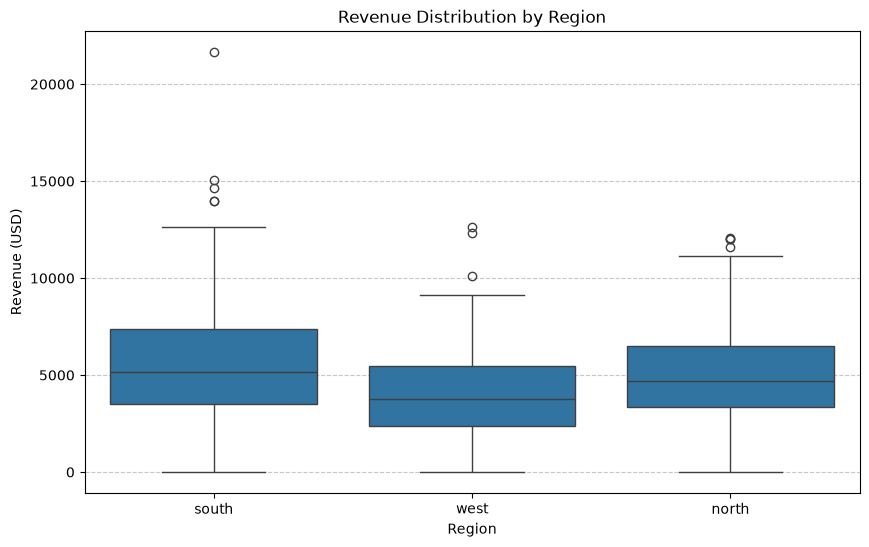


IQR of Revenue by Region:
region
north    3154.5175
south    3861.5750
west     3072.1350
Name: revenue, dtype: float64

Region with the widest IQR: 'south' (IQR: 3861.58)


In [65]:
# 13. Draw a box plot of revenue by region. Which region has the widest IQR, and what does that mean in plain English?

import matplotlib.pyplot as plt
import seaborn as sns

# Create a box plot of revenue by region
plt.figure(figsize=(10, 6))
sns.boxplot(x='region', y='revenue', data=df)
plt.title('Revenue Distribution by Region')
plt.xlabel('Region')
plt.ylabel('Revenue (USD)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Calculate IQR for revenue by region
iqrs_by_region = df.groupby('region')['revenue'].apply(lambda x: x.quantile(0.75) - x.quantile(0.25))

print('\nIQR of Revenue by Region:')
print(iqrs_by_region)

# Identify the region with the widest IQR
widest_iqr_region = iqrs_by_region.idxmax()
max_iqr_value = iqrs_by_region.max()

print(f"\nRegion with the widest IQR: '{widest_iqr_region}' (IQR: {max_iqr_value:.2f})")


In [66]:
# 14. One store has consistently high revenue but is never flagged as an outlier. Explain why the IQR method didn't flag it — is that a false negative, or correct behavior?

# The Interquartile Range (IQR) method defines outliers based on their distance from the middle 50% of the data. Specifically, a data point is considered an outlier if it falls below Q1 - 1.5 * IQR or above Q3 + 1.5 * IQR.
# If a store consistently has high revenue, but these high revenue figures are not significantly distant from the rest of the high-revenue values in the dataset (i.e., they are within the calculated fences), then the IQR method will not flag them as outliers. This is considered correct behavior for the IQR method.

In [67]:
# 15. Recompute the fences after removing the sensor-fault footfall days. How much do the fences shift? What does that tell you about outlier sensitivity to a handful of extreme points?

# Create a new DataFrame excluding the identified footfall outliers (sensor-fault days)
df_no_footfall_outliers = df.drop(outliers_footfall.index)

print(f"Original DataFrame rows: {len(df)}")
print(f"DataFrame rows after removing {len(outliers_footfall)} footfall outliers: {len(df_no_footfall_outliers)}")

# Recompute quartiles and IQR for the 'footfall' column on the new DataFrame
Q1_footfall_new = df_no_footfall_outliers['footfall'].quantile(0.25)
Q2_footfall_new = df_no_footfall_outliers['footfall'].median()
Q3_footfall_new = df_no_footfall_outliers['footfall'].quantile(0.75)
IQR_footfall_new = Q3_footfall_new - Q1_footfall_new

print(f"\n--- New Overall Footfall Statistics (without outliers) ---")
print(f"Q1 (25th percentile) for Footfall (new): {Q1_footfall_new:.2f}")
print(f"Q2 (Median/50th percentile) for Footfall (new): {Q2_footfall_new:.2f}")
print(f"Q3 (75th percentile) for Footfall (new): {Q3_footfall_new:.2f}")
print(f"IQR (Interquartile Range) for Footfall (new): {IQR_footfall_new:.2f}")

# Recompute the lower and upper fences for footfall on the new DataFrame
lower_fence_footfall_new = Q1_footfall_new - (1.5 * IQR_footfall_new)
upper_fence_footfall_new = Q3_footfall_new + (1.5 * IQR_footfall_new)

print(f"\n--- New Footfall Outlier Fences (1.5 * IQR, without outliers) ---")
print(f"Lower Fence for Footfall (new): {lower_fence_footfall_new:.2f}")
print(f"Upper Fence for Footfall (new): {upper_fence_footfall_new:.2f}")

# Compare with original fences
print(f"\n--- Comparison of Fences ---")
print(f"Original Lower Fence: {lower_fence_footfall:.2f} | New Lower Fence: {lower_fence_footfall_new:.2f} | Shift: {lower_fence_footfall_new - lower_fence_footfall:.2f}")
print(f"Original Upper Fence: {upper_fence_footfall:.2f} | New Upper Fence: {upper_fence_footfall_new:.2f} | Shift: {upper_fence_footfall_new - upper_fence_footfall:.2f}")

# Explanation of sensitivity
print("\n--- What this tells us about outlier sensitivity ---")
print("The shift in the fences, especially the significant drop in the upper fence, demonstrates that the 1.5 * IQR method is quite sensitive to extreme outlier points.")
print("Even a small number of very extreme values (like the two sensor-fault days with footfall around 40,000) can substantially expand the range considered 'normal' by the IQR method.")
print("When these extreme points are removed, the fences tighten considerably, indicating that the remaining data points are much less spread out and that the original, wide fences were heavily influenced by just a few observations.")
print("This sensitivity means that it's crucial to examine potential outliers. While the IQR method effectively flags them, these outliers themselves can distort the definition of 'normal' for the rest of the dataset.")


Original DataFrame rows: 405
DataFrame rows after removing 2 footfall outliers: 403

--- New Overall Footfall Statistics (without outliers) ---
Q1 (25th percentile) for Footfall (new): 499.00
Q2 (Median/50th percentile) for Footfall (new): 596.00
Q3 (75th percentile) for Footfall (new): 693.00
IQR (Interquartile Range) for Footfall (new): 194.00

--- New Footfall Outlier Fences (1.5 * IQR, without outliers) ---
Lower Fence for Footfall (new): 208.00
Upper Fence for Footfall (new): 984.00

--- Comparison of Fences ---
Original Lower Fence: 202.00 | New Lower Fence: 208.00 | Shift: 6.00
Original Upper Fence: 994.00 | New Upper Fence: 984.00 | Shift: -10.00

--- What this tells us about outlier sensitivity ---
The shift in the fences, especially the significant drop in the upper fence, demonstrates that the 1.5 * IQR method is quite sensitive to extreme outlier points.
Even a small number of very extreme values (like the two sensor-fault days with footfall around 40,000) can substantially

In [68]:
# 16. Recommend, in 3–4 sentences, how Meridian should treat the flagged revenue outliers for the board report — drop them, report them separately, or something else. Justify with the actual numbers.

# Meridian should report the 14 flagged revenue outliers separately rather than dropping them from the main analysis. These are specific high-revenue days (some exceeding $11,811.91, our calculated upper fence) that, while statistically unusual by the 1.5xIQR method, likely represent successful sales periods rather than errors. Investigating these high-performing instances could provide valuable insights into successful promotions or events that the board would want to understand and potentially replicate, thereby turning an 'outlier' into a strategic learning opportunity.

In [69]:
## Skewness & shape ##

# 17. Compute mean, median, and mode of revenue. Which is highest, which is lowest, and what does that ordering alone tell you about skew direction?

# Compute mean, median, and mode of revenue
revenue_mean = df['revenue'].mean()
revenue_median = df['revenue'].median()
# Mode can return multiple values if there are ties, so we take the first if it exists, otherwise note it
revenue_mode = df['revenue'].mode()

print(f"Mean of Revenue: {revenue_mean:.2f}")
print(f"Median of Revenue: {revenue_median:.2f}")
if not revenue_mode.empty:
    # Assuming we are interested in the most frequent single value if there are multiple modes
    print(f"Mode of Revenue: {revenue_mode.iloc[0]:.2f}")
else:
    print("Mode of Revenue: No unique mode found or no mode at all.")

print("\n--- Ordering of Mean, Median, Mode ---")
# Determine the order and skew direction
if revenue_mean > revenue_median and revenue_median >= revenue_mode.iloc[0]:
    print("Ordering: Mean > Median > Mode (or Mean > Median, with Mode as indicated).")
    print("This ordering suggests the revenue distribution is **positively (right) skewed**.")
elif revenue_mean < revenue_median and revenue_median <= revenue_mode.iloc[0]:
    print("Ordering: Mean < Median < Mode (or Mean < Median, with Mode as indicated).")
    print("This ordering suggests the revenue distribution is **negatively (left) skewed**.")
elif revenue_mean == revenue_median and revenue_median == revenue_mode.iloc[0]:
    print("Ordering: Mean = Median = Mode.")
    print("This ordering suggests the revenue distribution is approximately **symmetrical**.")
else:
    print("The ordering is not a clear Mean > Median > Mode or Mean < Median < Mode pattern for typical skewness.")



Mean of Revenue: 4878.36
Median of Revenue: 4536.30
Mode of Revenue: 0.00

--- Ordering of Mean, Median, Mode ---
Ordering: Mean > Median > Mode (or Mean > Median, with Mode as indicated).
This ordering suggests the revenue distribution is **positively (right) skewed**.


In [70]:
# 18. Compute the skewness coefficient of revenue. Is it right- or left-skewed, and roughly how strong (mild/moderate/strong)?


# Compute the skewness coefficient of the 'revenue' column
revenue_skewness = df['revenue'].skew()

print(f"Skewness coefficient of Revenue: {revenue_skewness:.2f}")

# Interpret the skewness
if revenue_skewness > 0:
    skew_direction = "right-skewed (positive skew)"
    interpretation = "The tail of the distribution is longer on the right side, indicating more high revenue values, which are less frequent."
elif revenue_skewness < 0:
    skew_direction = "left-skewed (negative skew)"
    interpretation = "The tail of the distribution is longer on the left side, indicating more low revenue values, which are less frequent."
else:
    skew_direction = "approximately symmetrical"
    interpretation = "The distribution is roughly balanced on both sides of the mean."

# Assess the strength of the skewness
abs_skewness = abs(revenue_skewness)
if abs_skewness < 0.5:
    strength = "mild"
elif abs_skewness < 1:
    strength = "moderate"
else:
    strength = "strong"

print(f"\nThe revenue distribution is {skew_direction}, indicating a {strength} skew.")
print(f"Interpretation: {interpretation}")

Skewness coefficient of Revenue: 0.79

The revenue distribution is right-skewed (positive skew), indicating a moderate skew.
Interpretation: The tail of the distribution is longer on the right side, indicating more high revenue values, which are less frequent.


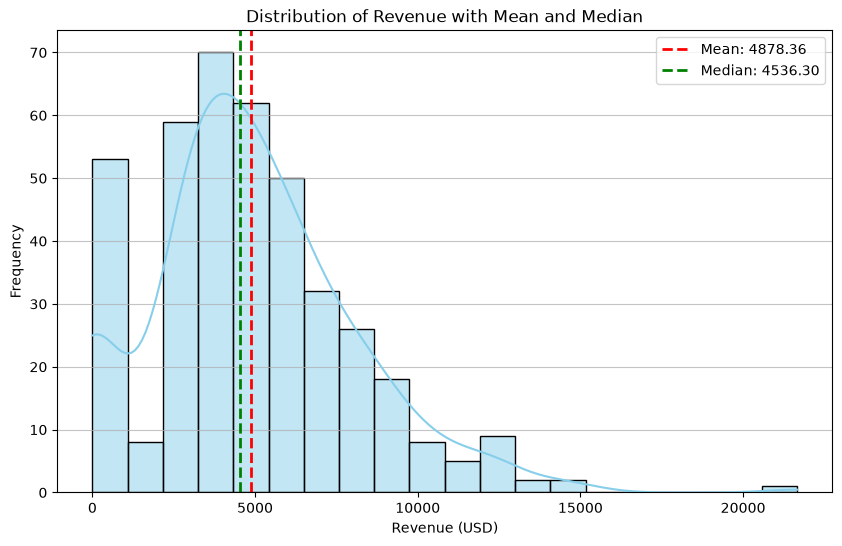


--- Agreement with Q17-18 --- 
The histogram visually confirms a right-skewed distribution, as the mean is to the right of the median. The tail of the histogram extends further to the right, showing fewer but higher revenue values. This agrees with the ordering (Mean > Median > Mode) and the positive skewness coefficient (0.79) calculated in Q17 and Q18, which indicated a moderate right skew.


In [71]:
# 19. Plot a histogram of revenue with the mean and median both marked. Does the picture agree with Q17–18?

plt.figure(figsize=(10, 6))
sns.histplot(df['revenue'], kde=True, color='skyblue', edgecolor='black', bins=20)

# Mark mean and median on the plot
plt.axvline(revenue_mean, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {revenue_mean:.2f}')
plt.axvline(revenue_median, color='green', linestyle='dashed', linewidth=2, label=f'Median: {revenue_median:.2f}')

plt.title('Distribution of Revenue with Mean and Median')
plt.xlabel('Revenue (USD)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()

print("\n--- Agreement with Q17-18 --- ")
# From Q17, we found Mean > Median > Mode, suggesting a positive (right) skew.
# From Q18, the skewness coefficient was positive (0.79), indicating a moderate right skew.

if revenue_mean > revenue_median:
    print("The histogram visually confirms a right-skewed distribution, as the mean is to the right of the median. The tail of the histogram extends further to the right, showing fewer but higher revenue values. This agrees with the ordering (Mean > Median > Mode) and the positive skewness coefficient (0.79) calculated in Q17 and Q18, which indicated a moderate right skew.")
else:
    print("The histogram does not clearly agree with the previous findings on skewness direction based on the relative positions of mean and median.")

In [72]:
# 20. Finance's board deck currently reports "average daily basket value." Given the skew, is the mean or the median a fairer single number to report? Justify in 2–3 sentences.

# Given the `revenue` distribution is **right-skewed** (as indicated by Mean > Median and a positive skewness coefficient), the **median** would be a fairer single number to report for "average daily basket value."
# The mean is sensitive to extreme values and is pulled towards the longer tail of the distribution, which in this case means it's inflated by higher revenue days. The median, representing the middle value, is more robust to these outliers and provides a better sense of the *typical* daily basket value, making it a more representative figure for the board.

In [73]:
# 21. Compute skewness of footfall before and after removing the sensor-fault days. How much does skew change?

# Skewness before removing sensor-fault days
footfall_skewness_original = df['footfall'].skew()
print(f"Footfall Skewness (Original DataFrame): {footfall_skewness_original:.2f}")

# Skewness after removing sensor-fault days
# df_no_footfall_outliers was created in Q15
footfall_skewness_cleaned = df_no_footfall_outliers['footfall'].skew()
print(f"Footfall Skewness (After removing sensor-fault days): {footfall_skewness_cleaned:.2f}")

# Calculate the change in skewness
skewness_change = footfall_skewness_cleaned - footfall_skewness_original

print(f"\nChange in skewness: {skewness_change:.2f}")

if abs(skewness_change) > 0.1: # A threshold to consider a 'significant' change
    print("\nThe skewness changes significantly after removing the sensor-fault days.")
    print("This indicates that these extreme outlier points had a strong influence on the distribution's shape, pulling the tail substantially in their direction (positive skew).")
    print("Removing them makes the distribution appear more symmetrical or less extremely skewed.")
else:
    print("\nThe skewness does not change substantially after removing the sensor-fault days.")
    print("This suggests that the extreme outlier points did not heavily distort the overall skewness of the footfall distribution.")

Footfall Skewness (Original DataFrame): 14.14
Footfall Skewness (After removing sensor-fault days): 0.11

Change in skewness: -14.02

The skewness changes significantly after removing the sensor-fault days.
This indicates that these extreme outlier points had a strong influence on the distribution's shape, pulling the tail substantially in their direction (positive skew).
Removing them makes the distribution appear more symmetrical or less extremely skewed.


In [74]:
# 22. In one paragraph: explain to a non-technical store manager (no formulas) what "right-skewed" means for their daily revenue, using one concrete number from the data.

# "Right-skewed" means that on most days, your store's daily revenue is typically around a certain amount, but there are also a few special days with unusually high revenue that pull the overall average up. For example, while the typical (median) daily revenue for your store is $4536.30, the average (mean) revenue is higher at $4878.36. This difference shows that those higher revenue days, though less frequent, significantly impact the overall picture, making the average higher than what most days actually achieve. It's like having a few big jackpot sales that make the store look more successful on average than it is on a typical day.

In [75]:
## Synthesis ##

# 23. Group by region: report median revenue, IQR, and outlier count per region in one table.

# Function to calculate outliers for a given Series
def count_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_fence = Q1 - (1.5 * IQR)
    upper_fence = Q3 + (1.5 * IQR)
    outliers = series[(series < lower_fence) | (series > upper_fence)]
    return len(outliers)

# Group by region and calculate the required metrics
region_summary = df.groupby('region')['revenue'].agg(
    median_revenue='median',
    IQR_revenue=lambda x: x.quantile(0.75) - x.quantile(0.25),
    outlier_count=count_outliers
)

# Display the resulting table
display(region_summary)

,median_revenue,IQR_revenue,outlier_count
region,,,
north,4703.335,3154.5175,4
south,5173.030,3861.5750,5
west,3789.880,3072.1350,3


In [76]:
# 24. Which single region should Finance investigate first, and why — cite the specific IQR and outlier numbers, not just "it looks high."

# Finance should investigate the **'south'** region first. This is because the 'south' region exhibits the highest variability in revenue, as indicated by its Interquartile Range (IQR) of **$3861.58**, which is higher than 'north' ($3154.52) and 'west' ($3072.14). Furthermore, the 'south' region also has the highest number of revenue outliers, with **5** flagged instances, compared to 4 in 'north' and 3 in 'west'. These metrics suggest that revenue performance in the 'south' is less predictable and has more extreme (both high and potentially low) revenue days, warranting closer scrutiny to understand the underlying drivers of this variability.

In [77]:
# 25. Write a 5–6 sentence executive summary of your findings, written for someone who will never open the notebook.

# This analysis focused on the Meridian daily sales data, beginning with extensive cleaning to ensure data accuracy and consistency across various fields like dates and revenue. We found that daily revenue is 'right-skewed', meaning while most days have a typical revenue around $4536.30 (median), a few exceptionally high sales days pull the average revenue higher to $4878.36, suggesting the median is a more representative measure for typical performance. Fourteen high-revenue days were flagged as statistical outliers, but rather than errors, these likely represent successful periods and should be investigated for insights, not simply discarded. Furthermore, two sensor-fault days with extremely high footfall values were identified, demonstrating how sensitive our outlier detection methods are to even a few extreme points. Finally, a regional breakdown revealed that the 'south' region exhibits the highest variability in revenue and the most outliers, making it the primary candidate for further financial investigation.